# Ridge regression on California housing

Out of class project. We fit a ridge regression model to the California housing data and use it as a
testbed for six optimizers: gradient descent, Newton, BFGS, L-BFGS, SGD and Adam.

The problem is a convex quadratic, so the "right" answer is known in closed form. That lets us measure
every method against the exact minimizer and see where the theory from the lectures (linear rate for GD
that depends on the condition number, quadratic for Newton, superlinear for quasi-Newton) holds up on real data.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda v: f"{v:.3g}")

# Data

20,640 census block groups, 8 numeric features, target is median house value (in $100k).

In [2]:
housing = fetch_california_housing()
X_raw, y_raw = housing.data, housing.target
print(X_raw.shape, housing.feature_names)

corr = np.corrcoef(X_raw, rowvar=False)
np.fill_diagonal(corr, 0)
i, j = np.unravel_index(np.abs(corr).argmax(), corr.shape)
print(f"most correlated pair: {housing.feature_names[i]} / {housing.feature_names[j]} ({corr[i, j]:.2f})")

(20640, 8) ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
most correlated pair: Latitude / Longitude (-0.92)


In [3]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.2, random_state=0)

# center the target with the training mean so the model needs no intercept
y_mean = y_train.mean()
y_train, y_test = y_train - y_mean, y_test - y_mean

# a few block groups have absurd values (AveOccup up to ~1200, AveRooms up to ~140). Cubing those
# wrecks the polynomial features on the test set, so clip each column to the training 0.5-99.5% range
lo, hi = np.percentile(X_train_raw, [0.5, 99.5], axis=0)
X_train_raw, X_test_raw = np.clip(X_train_raw, lo, hi), np.clip(X_test_raw, lo, hi)

With only 8 features the problem is tiny and well behaved, so there is not much to separate the methods.
To get a harder and more realistic problem we expand the features with polynomial terms of degree 1 to 4
(8, 44, 164 and 494 columns). Powers and products of correlated features are nearly linear combinations
of each other, so the Hessian gets badly conditioned as the degree goes up.

In [4]:
def build(degree):
    poly = PolynomialFeatures(degree, include_bias=False)
    scaler = StandardScaler()
    A = scaler.fit_transform(poly.fit_transform(X_train_raw))
    A_test = scaler.transform(poly.transform(X_test_raw))
    return A, A_test


data = {d: build(d) for d in range(1, 5)}
{d: A.shape[1] for d, (A, _) in data.items()}

{1: 8, 2: 44, 3: 164, 4: 494}

# Ridge objective

$$f(w) = \frac{1}{2n}\lVert Xw - y\rVert^2 + \frac{\lambda}{2}\lVert w\rVert^2$$

$$\nabla f(w) = \frac{1}{n}X^T(Xw - y) + \lambda w \qquad H = \frac{1}{n}X^TX + \lambda I$$

The Hessian does not depend on $w$ and is positive definite for any $\lambda > 0$. Its condition number
$\kappa = \lambda_{max}/\lambda_{min}$ is what controls how hard the problem is for first-order methods.
The exact solution is $w^* = H^{-1}\frac{1}{n}X^Ty$.

In [5]:
class RidgeProblem:
    def __init__(self, X, y, lam):
        self.X, self.y, self.lam = X, y, lam
        self.n, self.p = X.shape
        self.calls = dict(f=0, g=0, h=0)
        self.w_star = np.linalg.solve(self.hess(None), X.T @ y / self.n)
        self.f_star = self._f(self.w_star)
        self.calls = dict(f=0, g=0, h=0)

    # uncounted versions, used for logging and for the reference solution
    def _f(self, w):
        r = self.X @ w - self.y
        return r @ r / (2 * self.n) + 0.5 * self.lam * w @ w

    def _grad(self, w):
        return self.X.T @ (self.X @ w - self.y) / self.n + self.lam * w

    # counted versions, used by the solvers
    def f(self, w):
        self.calls["f"] += 1
        return self._f(w)

    def grad(self, w):
        self.calls["g"] += 1
        return self._grad(w)

    def hess(self, w):
        # recomputed on every call on purpose: a generic Newton code would not know H is constant
        self.calls["h"] += 1
        return self.X.T @ self.X / self.n + self.lam * np.eye(self.p)

# Line search and bookkeeping

Same backtracking (Armijo) line search as in class, $c = 0.1$, $\rho = 1/2$.

`History` logs the gap to the true optimum after every iteration. The time spent computing those metrics
is not counted, so the wall clock numbers only reflect the optimizer itself.

In [6]:
def backtrack(prob, w, fw, g, d, alpha0=1.0, c=0.1, rho=0.5):
    alpha, slope = alpha0, g @ d
    for _ in range(60):
        if prob.f(w + alpha * d) <= fw + c * alpha * slope:
            break
        alpha *= rho
    return alpha


class History:
    def __init__(self, prob):
        self.prob = prob
        self.f, self.err, self.gnorm, self.t = [], [], [], []
        self.elapsed, self._mark = 0.0, None

    def record(self, w):
        now = time.perf_counter()
        if self._mark is not None:
            self.elapsed += now - self._mark
        with np.errstate(all="ignore"):
            self.f.append(self.prob._f(w) - self.prob.f_star)
            self.err.append(np.linalg.norm(w - self.prob.w_star))
            self.gnorm.append(np.linalg.norm(self.prob._grad(w)))
        self.t.append(self.elapsed)
        self._mark = time.perf_counter()

# Solvers

All of them start from $w = 0$. The four deterministic methods stop when $\lVert\nabla f\rVert < 10^{-6}$
or at `max_iter`. SGD and Adam are run for a fixed number of epochs, one epoch being one pass over the data in
mini-batches.

In [7]:
def gd(prob, init="one", max_iter=2000, tol=1e-6, c=0.1, rho=0.5):
    # init="prev" is the initial step guess from the notes: alpha0 = alpha_prev * (g_prev.g_prev) / (g.g)
    w = np.zeros(prob.p)
    hist = History(prob)
    hist.record(w)
    fw, g = prob.f(w), prob.grad(w)
    alpha = 1.0
    for k in range(max_iter):
        if np.linalg.norm(g) < tol:
            break
        alpha0 = 1.0
        if init == "prev" and k > 0:
            alpha0 = alpha * (g_prev @ g_prev) / (g @ g)
        alpha = backtrack(prob, w, fw, g, -g, alpha0, c, rho)
        g_prev = g
        w = w - alpha * g
        fw, g = prob.f(w), prob.grad(w)
        hist.record(w)
    return w, hist


def gd_exact(prob, max_iter=2000, tol=1e-12):
    # steepest descent with the exact line search a quadratic allows; only used to check the rate in the notes
    w = np.zeros(prob.p)
    H = prob.hess(w)
    hist = History(prob)
    hist.record(w)
    for _ in range(max_iter):
        g = prob._grad(w)
        if np.linalg.norm(g) < tol:
            break
        w = w - (g @ g) / (g @ H @ g) * g
        hist.record(w)
    return w, hist


def newton(prob, max_iter=50, tol=1e-6, c=0.1, rho=0.5):
    w = np.zeros(prob.p)
    hist = History(prob)
    hist.record(w)
    fw, g = prob.f(w), prob.grad(w)
    for _ in range(max_iter):
        if np.linalg.norm(g) < tol:
            break
        d = np.linalg.solve(prob.hess(w), -g)
        alpha = backtrack(prob, w, fw, g, d, 1.0, c, rho)
        w = w + alpha * d
        fw, g = prob.f(w), prob.grad(w)
        hist.record(w)
    return w, hist

In [8]:
def bfgs(prob, max_iter=2000, tol=1e-6, c=0.1, rho=0.5):
    # keeps F ~ H^-1 directly (Sherman-Morrison form of the update), so no linear solve per iteration
    w = np.zeros(prob.p)
    hist = History(prob)
    hist.record(w)
    fw, g = prob.f(w), prob.grad(w)
    F = np.eye(prob.p)
    scaled = False
    for _ in range(max_iter):
        if np.linalg.norm(g) < tol:
            break
        d = -F @ g
        alpha = backtrack(prob, w, fw, g, d, 1.0, c, rho)
        s = alpha * d
        w = w + s
        fw, g_new = prob.f(w), prob.grad(w)
        y, g = g_new - g, g_new
        sy = s @ y
        # Armijo does not enforce the curvature condition, skip the update if s.y is not safely positive
        if sy > 1e-12:
            if not scaled:
                # rescale the identity to the size of H^-1 along the first step
                F = (sy / (y @ y)) * np.eye(prob.p)
                scaled = True
            Fy = F @ y
            F = F + (sy + y @ Fy) / sy**2 * np.outer(s, s) - (np.outer(Fy, s) + np.outer(s, Fy)) / sy
        hist.record(w)
    return w, hist


def lbfgs(prob, m=10, max_iter=2000, tol=1e-6, c=0.1, rho=0.5):
    w = np.zeros(prob.p)
    hist = History(prob)
    hist.record(w)
    fw, g = prob.f(w), prob.grad(w)
    S, Y = [], []
    for _ in range(max_iter):
        if np.linalg.norm(g) < tol:
            break
        # two-loop recursion for -F g using the last m (s, y) pairs
        q, a = g.copy(), []
        for s, y in zip(reversed(S), reversed(Y)):
            a.append((s @ q) / (s @ y))
            q -= a[-1] * y
        if S:
            q *= (S[-1] @ Y[-1]) / (Y[-1] @ Y[-1])
        for (s, y), a_i in zip(zip(S, Y), reversed(a)):
            q += (a_i - (y @ q) / (s @ y)) * s
        d = -q
        alpha = backtrack(prob, w, fw, g, d, 1.0, c, rho)
        s = alpha * d
        w = w + s
        fw, g_new = prob.f(w), prob.grad(w)
        y, g = g_new - g, g_new
        if s @ y > 1e-12:
            S.append(s)
            Y.append(y)
            if len(S) > m:
                S.pop(0)
                Y.pop(0)
        hist.record(w)
    return w, hist

In [9]:
def minibatches(prob, rng, batch):
    idx = rng.permutation(prob.n)
    for i in range(0, prob.n, batch):
        yield idx[i:i + batch]


def batch_grad(prob, w, b):
    Xb = prob.X[b]
    return Xb.T @ (Xb @ w - prob.y[b]) / len(b) + prob.lam * w


def sgd(prob, lr=1e-3, decay=0.0, batch=128, epochs=50, seed=0):
    rng = np.random.default_rng(seed)
    w = np.zeros(prob.p)
    hist = History(prob)
    hist.record(w)
    t = 0
    with np.errstate(all="ignore"):
        for _ in range(epochs):
            for b in minibatches(prob, rng, batch):
                w = w - lr / (1 + decay * t) * batch_grad(prob, w, b)
                t += 1
            hist.record(w)
            if not np.isfinite(w).all():
                break
    return w, hist


def adam(prob, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8, batch=128, epochs=50, seed=0):
    rng = np.random.default_rng(seed)
    w = np.zeros(prob.p)
    m, v = np.zeros(prob.p), np.zeros(prob.p)
    hist = History(prob)
    hist.record(w)
    t = 0
    with np.errstate(all="ignore"):
        for _ in range(epochs):
            for b in minibatches(prob, rng, batch):
                g = batch_grad(prob, w, b)
                t += 1
                m = beta1 * m + (1 - beta1) * g
                v = beta2 * v + (1 - beta2) * g * g
                w = w - lr * (m / (1 - beta1**t)) / (np.sqrt(v / (1 - beta2**t)) + eps)
            hist.record(w)
            if not np.isfinite(w).all():
                break
    return w, hist


SOLVERS = dict(gd=gd, newton=newton, bfgs=bfgs, lbfgs=lbfgs, sgd=sgd, adam=adam)

## Sanity checks

Before trusting any comparison: check the analytic gradient against finite differences and make sure every
solver lands on the closed-form solution.

In [10]:
def rmse(w, A_test, y_test):
    return np.sqrt(np.mean((A_test @ w - y_test) ** 2))


A, A_test = data[2]
prob = RidgeProblem(A, y_train, lam=1e-2)

rng = np.random.default_rng(1)
w0, v = rng.standard_normal(prob.p), rng.standard_normal(prob.p)
h = 1e-6
fd = (prob._f(w0 + h * v) - prob._f(w0 - h * v)) / (2 * h)
print("directional derivative: analytic %.8f  finite diff %.8f" % (prob._grad(w0) @ v, fd))

for name in ["gd", "newton", "bfgs", "lbfgs"]:
    kw = {} if name == "newton" else dict(max_iter=5000)
    w, hist = SOLVERS[name](prob, **kw)
    print(f"{name:7s} |w - w*| = {np.linalg.norm(w - prob.w_star):.2e}")

directional derivative: analytic -14.47629782  finite diff -14.47629776


gd      |w - w*| = 7.14e-05
newton  |w - w*| = 0.00e+00


bfgs    |w - w*| = 7.99e-05
lbfgs   |w - w*| = 4.22e-05


# Conditioning

First look at $\kappa$ of the Hessian for each polynomial degree and a few values of $\lambda$.
$\lambda$ shifts every eigenvalue up by the same amount, so it is the main knob for conditioning.

In [11]:
lams = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
spectra = {d: np.linalg.eigvalsh(A.T @ A / len(A)).clip(min=0) for d, (A, _) in data.items()}

kappa_table = pd.DataFrame(
    {f"lam={l:g}": {f"deg {d} (p={data[d][0].shape[1]})": (ev[-1] + l) / (ev[0] + l) for d, ev in spectra.items()}
     for l in lams}
)
kappa_table

,lam=0.0001,lam=0.001,lam=0.01,lam=0.1,lam=1
deg 1 (p=8),43.8,43,36.4,14.8,2.95
deg 2 (p=44),1.07e+05,1.08e+04,1.08e+03,109,11.8
deg 3 (p=164),4.16e+05,4.16e+04,4.16e+03,417,42.6
deg 4 (p=494),1.3e+06,1.3e+05,1.3e+04,1.3e+03,131


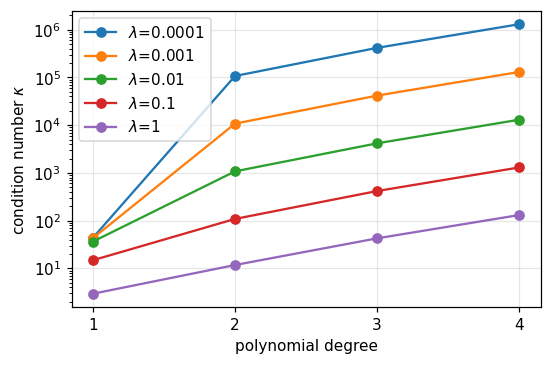

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for l in lams:
    ax.plot(list(spectra), [(ev[-1] + l) / (ev[0] + l) for ev in spectra.values()], "o-", label=f"$\\lambda$={l:g}")
ax.set_yscale("log")
ax.set_xticks(list(spectra))
ax.set_xlabel("polynomial degree")
ax.set_ylabel("condition number $\\kappa$")
ax.legend()
plt.show()

Even the raw features (degree 1) have $\kappa$ in the tens, and by degree 3 an unregularized fit would be
numerically singular ($\lambda_{min}$ is around $10^{-11}$). Ridge keeps $\kappa$ bounded by roughly
$\lambda_{max}/\lambda$.

# Does GD follow the rate from the notes?

For steepest descent with exact line search on a quadratic,
$f(x_{k+1}) - f^* \le \left(\frac{\kappa-1}{\kappa+1}\right)^2 (f(x_k) - f^*)$. A quadratic is the one case
where exact line search is cheap, so we can check the bound directly.

degree 1: kappa=36.4  bound=0.8960  observed mean=0.8753  max=0.8940


degree 2: kappa=1077.3  bound=0.9963  observed mean=0.9935  max=0.9958


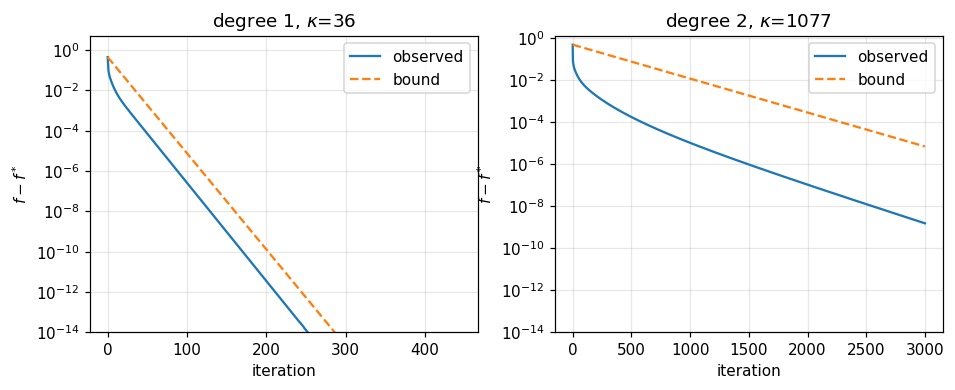

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, degree in zip(axes, (1, 2)):
    prob = RidgeProblem(data[degree][0], y_train, lam=1e-2)
    ev = np.linalg.eigvalsh(prob.hess(None))
    kappa = ev[-1] / ev[0]
    bound = ((kappa - 1) / (kappa + 1)) ** 2

    _, hist = gd_exact(prob, max_iter=3000)
    gap = np.array(hist.f)
    mask = gap[1:] > 1e-9       # below this f - f* is mostly rounding error and the ratios are noise
    ratios = gap[1:][mask] / gap[:-1][mask]
    print(f"degree {degree}: kappa={kappa:.1f}  bound={bound:.4f}  "
          f"observed mean={np.exp(np.log(ratios).mean()):.4f}  max={ratios.max():.4f}")

    ax.semilogy(gap.clip(min=1e-16), label="observed")
    ax.semilogy(gap[0] * bound ** np.arange(len(gap)), "--", label="bound")
    ax.set_ylim(1e-14, None)
    ax.set_title(f"degree {degree}, $\\kappa$={kappa:.0f}")
    ax.set_xlabel("iteration")
    ax.set_ylabel("$f - f^*$")
    ax.legend()
plt.show()

The bound holds, and it is close to tight: at degree 1 the per-iteration ratio settles at 0.894 against a
bound of 0.896, and at degree 2 the largest observed ratio is 0.9958 against 0.9963. With
$\kappa \approx 10^3$ every iteration only removes about 0.4% of the remaining gap.

# Comparing all six methods

Degree 3 (164 features), $\lambda = 10^{-2}$, so $\kappa \approx 4\cdot10^3$.

SGD and Adam have a learning rate that has to be chosen, and they are sensitive to it. We pick it with a
small grid search, using the final gap to the optimum after 50 epochs. The same grid is reused later.

In [14]:
SGD_GRID = [dict(lr=lr, decay=dc) for lr in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2) for dc in (0.0, 1e-3)]
ADAM_GRID = [dict(lr=lr) for lr in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2)]


def tune(method, prob, grid):
    rows = []
    for params in grid:
        _, hist = SOLVERS[method](prob, **params)
        gap = hist.f[-1] if np.isfinite(hist.f[-1]) else np.inf
        rows.append({**params, "final gap": gap})
    table = pd.DataFrame(rows).sort_values("final gap").reset_index(drop=True)
    best = table.iloc[0].drop("final gap").to_dict()
    return best, table


A, A_test = data[3]
prob3 = RidgeProblem(A, y_train, lam=1e-2)

sgd_params, sgd_table = tune("sgd", prob3, SGD_GRID)
adam_params, adam_table = tune("adam", prob3, ADAM_GRID)
print(sgd_table.head(6).to_string(), "\n")
print(adam_table.to_string())

     lr  decay  final gap
0  0.01      0    0.00148
1  0.01  0.001    0.00371
2 0.003      0      0.004
3 0.001      0     0.0112
4 0.003  0.001     0.0119
5 0.001  0.001     0.0332 

      lr  final gap
0  0.001    0.00136
1 0.0003    0.00369
2  0.003    0.00517
3 0.0001    0.00935
4   0.01     0.0126


In [15]:
def run(method, prob, **kw):
    prob.calls = dict(f=0, g=0, h=0)
    w, hist = SOLVERS[method](prob, **kw)
    return dict(method=method, w=w, hist=hist, calls=dict(prob.calls))


def summarize(results, prob, A_test, tol=1e-6):
    rows = []
    for r in results:
        h = r["hist"]
        rows.append({
            "method": r["method"],
            "iters": len(h.f) - 1,
            "time (s)": h.t[-1],
            "f evals": r["calls"]["f"],
            "grad evals": r["calls"]["g"],
            "hess evals": r["calls"]["h"],
            "f - f*": h.f[-1],
            "|w - w*|": h.err[-1],
            "|grad|": h.gnorm[-1],
            "converged": h.gnorm[-1] < tol,
            "test RMSE": rmse(r["w"], A_test, y_test),
        })
    return pd.DataFrame(rows).set_index("method")


STYLE = dict(gd="tab:blue", newton="tab:red", bfgs="tab:green", lbfgs="tab:olive", sgd="tab:purple", adam="tab:orange")


def plot_histories(results, title=None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for r in results:
        h = r["hist"]
        kw = dict(color=STYLE[r["method"]], label=r["method"])
        axes[0].semilogy(np.maximum(h.f, 1e-16), **kw)
        axes[1].semilogy(h.t, np.maximum(h.f, 1e-16), **kw)
    axes[0].set_xlabel("iteration (epoch for sgd / adam)")
    axes[1].set_xlabel("wall time (s)")
    for ax in axes:
        ax.set_ylabel("$f - f^*$")
        ax.set_ylim(1e-14, None)
    axes[1].set_xscale("log")
    axes[1].set_xlim(left=1e-3)
    axes[0].legend()
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()

In [16]:
main = [
    run("gd", prob3, max_iter=3000),
    run("newton", prob3),
    run("bfgs", prob3, max_iter=3000),
    run("lbfgs", prob3, max_iter=3000),
    run("sgd", prob3, **sgd_params),
    run("adam", prob3, **adam_params),
]
summarize(main, prob3, A_test)

,iters,time (s),f evals,grad evals,hess evals,f - f*,|w - w*|,|grad|,converged,test RMSE
method,,,,,,,,,,
gd,3000,5.81,18582,3001,0,1.95e-05,0.0555,0.000855,False,0.618
newton,1,0.00503,3,2,1,0,0,1.58e-14,True,0.618
bfgs,3000,3.44,6006,3001,0,4.8e-11,8.86e-05,1.17e-06,False,0.618
lbfgs,552,0.665,1137,553,0,1.43e-11,4.1e-05,9.99e-07,True,0.618
sgd,50,0.218,0,0,0,0.00148,0.304,0.178,False,0.623
adam,50,0.26,0,0,0,0.00136,0.242,0.231,False,0.623


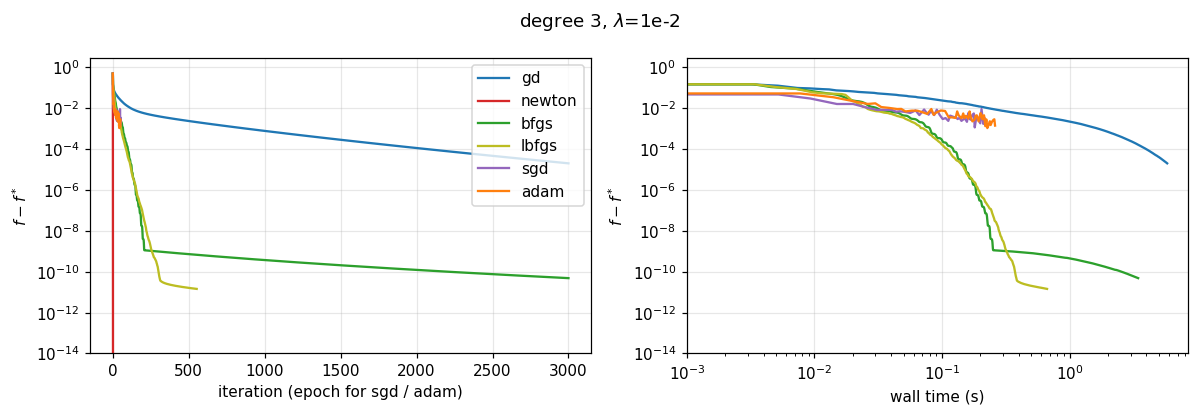

In [17]:
plot_histories(main, "degree 3, $\\lambda$=1e-2")

Newton lands on $w^*$ in a single step: the model is exactly quadratic, so the Newton step is exact and
$\alpha = 1$ passes the Armijo test. L-BFGS reaches the gradient tolerance in 552 iterations. BFGS is
just above it after 3000 (gap $5\cdot10^{-11}$, gradient norm $1.2\cdot10^{-6}$), and GD has only
got down to $2\cdot10^{-5}$. SGD and Adam bounce around $10^{-3}$ because of the mini-batch noise, which
is expected: they are not built to converge to high accuracy.

The test RMSE is 0.618 for all four deterministic methods and 0.623 for SGD and Adam, so for prediction
the difference between a gap of $10^{-3}$ and $10^{-11}$ hardly matters here. The accuracy only matters if
the exact minimizer is the goal.

## Initial step length for GD

The notes suggest that GD has no natural step scale, and propose reusing the previous step's first order
decrease to pick $\alpha_0$ instead of always starting the backtracking at 1. Same problem as above.

In [18]:
gd_init = [run("gd", prob3, init=i, max_iter=3000) for i in ("one", "prev")]
for r, i in zip(gd_init, ("one", "prev")):
    h = r["hist"]
    print(f"alpha0 = {i:5s} iters={len(h.f) - 1:5d}  f evals={r['calls']['f']:6d}  "
          f"grad evals={r['calls']['g']:5d}  f-f*={h.f[-1]:.2e}  time={h.t[-1]:.2f}s")

alpha0 = one   iters= 3000  f evals= 18582  grad evals= 3001  f-f*=1.95e-05  time=5.89s
alpha0 = prev  iters= 3000  f evals=  6029  grad evals= 3001  f-f*=1.97e-05  time=3.35s


Both runs stop at the 3000 iteration cap with about the same gap, so the rule does not buy more progress per
iteration. What it saves is backtracking: 6029 function evaluations instead of 18582, and roughly half
the time. It finds about the same step sizes more cheaply.

## Effect of $\lambda$

Same comparison at degree 2 for a range of $\lambda$. Smaller $\lambda$ means larger $\kappa$.
Iteration counts are for reaching $\lVert\nabla f\rVert < 10^{-6}$ (capped at 5000).

In [19]:
A, A_test = data[2]
rows = []
for lam in [1.0, 1e-1, 1e-2, 1e-3, 1e-4]:
    prob = RidgeProblem(A, y_train, lam)
    ev = np.linalg.eigvalsh(prob.hess(None))
    row = {"lambda": lam, "kappa": ev[-1] / ev[0]}
    for m in ["gd", "newton", "bfgs", "lbfgs"]:
        r = run(m, prob, **({} if m == "newton" else dict(max_iter=5000)))
        row[m] = len(r["hist"].f) - 1
    rows.append(row)
pd.DataFrame(rows).set_index("lambda")

,kappa,gd,newton,bfgs,lbfgs
lambda,,,,,
1,11.8,57,1,23,22
0.1,109,378,1,77,52
0.01,1.08e+03,3521,1,595,169
0.001,1.08e+04,5000,1,1824,607
0.0001,1.07e+05,5000,1,313,1286


Newton is always one iteration. GD scales roughly with $\kappa$ (57, 378 and 3521 iterations for
$\kappa$ = 12, 109 and 1077) and hits the cap for the two smallest $\lambda$. BFGS and L-BFGS grow more slowly
but irregularly: BFGS needs 313 iterations at $\lambda = 10^{-4}$ and 1824 at $10^{-3}$, fewer for the harder
problem. We did not dig into why. The line search only enforces Armijo, not the Wolfe curvature condition,
so skipped updates are a possible suspect.

# Scaling with problem size

Same $\lambda = 10^{-2}$ for polynomial degree 1 to 4. For each degree the SGD and Adam learning rates are
tuned again. Memory is the size of the optimizer state only (the data matrix is the same for everyone):
$p$ for GD and SGD, $p^2$ for Newton and BFGS, $2mp$ for L-BFGS with $m=10$, $3p$ for Adam.

In [20]:
lam = 1e-2
MEM = dict(gd=lambda p: p, newton=lambda p: p * p, bfgs=lambda p: p * p,
           lbfgs=lambda p: 2 * 10 * p, sgd=lambda p: p, adam=lambda p: 3 * p)

rows, scaling = [], {}
for degree in range(1, 5):
    A, A_test = data[degree]
    prob = RidgeProblem(A, y_train, lam)
    ev = np.linalg.eigvalsh(prob.hess(None))
    sgd_p, _ = tune("sgd", prob, SGD_GRID)
    adam_p, _ = tune("adam", prob, ADAM_GRID)

    results = [
        run("gd", prob, max_iter=3000),
        run("newton", prob),
        run("bfgs", prob, max_iter=3000),
        run("lbfgs", prob, max_iter=3000),
        run("sgd", prob, **sgd_p),
        run("adam", prob, **adam_p),
    ]
    scaling[degree] = results
    for r in results:
        h = r["hist"]
        rows.append({
            "degree": degree, "p": prob.p, "kappa": ev[-1] / ev[0], "method": r["method"],
            "iters": len(h.f) - 1, "time (s)": h.t[-1], "f - f*": h.f[-1],
            "converged": h.gnorm[-1] < 1e-6, "test RMSE": rmse(r["w"], A_test, y_test),
            "memory (MB)": 8 * MEM[r["method"]](prob.p) / 1e6,
        })
scaling_df = pd.DataFrame(rows)
scaling_df.pivot(index="method", columns="degree", values="time (s)")

degree,1,2,3,4
method,,,,
adam,0.0782,0.107,0.29,0.51
bfgs,0.00264,0.179,3.96,10.8
gd,0.0278,1.22,5.96,23.4
lbfgs,0.00461,0.0572,0.723,6.84
newton,0.000312,0.0011,0.00543,0.0307
sgd,0.0409,0.0719,0.254,0.505


In [21]:
print("iterations (epochs for sgd / adam)")
display(scaling_df.pivot(index="method", columns="degree", values="iters"))
print("final f - f*")
display(scaling_df.pivot(index="method", columns="degree", values="f - f*"))
print("optimizer state (MB)")
display(scaling_df.pivot(index="method", columns="degree", values="memory (MB)"))

iterations (epochs for sgd / adam)


degree,1,2,3,4
method,,,,
adam,50,50,50,50
bfgs,17,595,3000,3000
gd,186,3000,3000,3000
lbfgs,17,169,552,1972
newton,1,1,1,1
sgd,50,50,50,50


final f - f*


degree,1,2,3,4
method,,,,
adam,5.25e-05,0.00113,0.00136,0.0032
bfgs,1.76e-13,3.72e-11,4.8e-11,2.58e-10
gd,8.3e-12,3.03e-10,1.95e-05,3.76e-06
lbfgs,2.2e-14,1.11e-11,1.43e-11,2.03e-11
newton,0,0,0,0
sgd,3.68e-05,0.00103,0.00148,0.00311


optimizer state (MB)


degree,1,2,3,4
method,,,,
adam,0.000192,0.00106,0.00394,0.0119
bfgs,0.000512,0.0155,0.215,1.95
gd,6.4e-05,0.000352,0.00131,0.00395
lbfgs,0.00128,0.00704,0.0262,0.079
newton,0.000512,0.0155,0.215,1.95
sgd,6.4e-05,0.000352,0.00131,0.00395


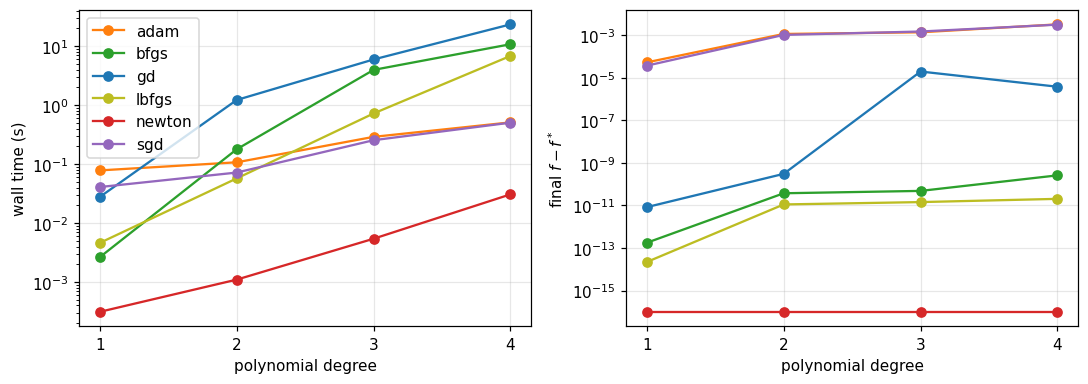

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for m, grp in scaling_df.groupby("method"):
    axes[0].semilogy(grp["degree"], grp["time (s)"], "o-", color=STYLE[m], label=m)
    axes[1].semilogy(grp["degree"], grp["f - f*"].clip(lower=1e-16), "o-", color=STYLE[m], label=m)
axes[0].set_ylabel("wall time (s)")
axes[1].set_ylabel("final $f - f^*$")
for ax in axes:
    ax.set_xticks(range(1, 5))
    ax.set_xlabel("polynomial degree")
axes[0].legend()
fig.tight_layout()
plt.show()

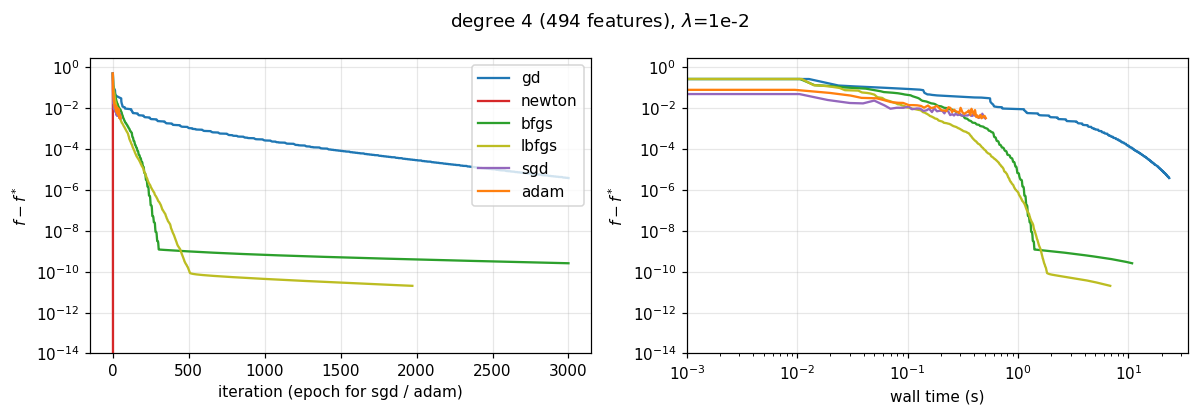

In [23]:
plot_histories(scaling[4], "degree 4 (494 features), $\\lambda$=1e-2")

Newton is the fastest at every degree, including degree 4 with 494 features (about 0.03 s). Forming the
Hessian costs $np^2 \approx 4\cdot10^9$ flops and the solve $p^3 \approx 10^8$, once each, which is little next to
thousands of line searched iterations of the other methods. The usual argument against Newton
needs $p$ in the thousands or more, which we did not reach.

Among the iterative methods L-BFGS is faster than BFGS from degree 2 on (6.8 s vs 10.8 s at degree 4, with
fewer iterations), and it needs 0.08 MB of state against 1.95 MB. GD from degree 2 and BFGS from degree 3 hit the
3000 iteration cap without meeting the tolerance, so their times are lower bounds. SGD and Adam take about
the same time at every degree (a fixed 50 epochs) but their final gap goes up from about $5\cdot10^{-5}$ to
$3\cdot10^{-3}$ as the problem gets harder.

Timings come from a single run on a laptop with multithreaded BLAS, so only the large differences mean much.

# Does ridge actually help?

Test RMSE of the exact ridge solution as a function of $\lambda$. This is separate from the optimizer
comparison: it is the reason to regularize in the first place, and tells us which $\lambda$ values are
worth caring about. Uses the eigendecomposition of $X^TX/n$ so the whole path is cheap.

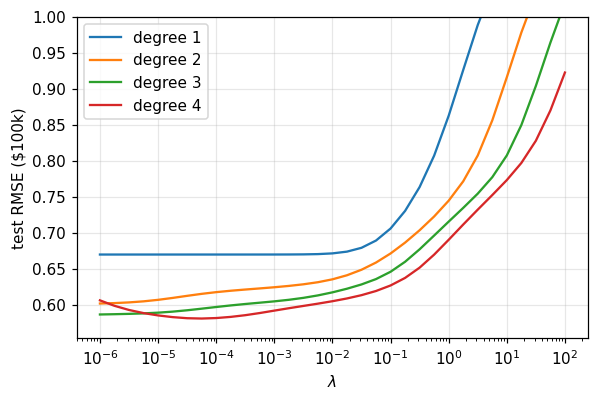

,best lambda,test RMSE
1,1e-06,0.67
2,1e-06,0.602
3,1e-06,0.587
4,5.62e-05,0.581


In [24]:
lam_grid = np.logspace(-6, 2, 33)
fig, ax = plt.subplots(figsize=(6, 3.8))
best = {}
for degree, (A, A_test) in data.items():
    ev, V = np.linalg.eigh(A.T @ A / len(A))
    ev = ev.clip(min=0)
    b = V.T @ (A.T @ y_train / len(A))
    errs = [rmse(V @ (b / (ev + l)), A_test, y_test) for l in lam_grid]
    best[degree] = (lam_grid[int(np.argmin(errs))], min(errs))
    ax.semilogx(lam_grid, errs, label=f"degree {degree}")
ax.set_xlabel("$\\lambda$")
ax.set_ylabel("test RMSE ($100k)")
ax.set_ylim(None, 1.0)
ax.legend()
plt.show()
pd.DataFrame(best, index=["best lambda", "test RMSE"]).T

Less than expected. The curves are flat for $\lambda \lesssim 10^{-3}$ and get worse above $10^{-2}$ for
degrees 1 to 3. Only degree 4 gains from regularization (0.581 at $\lambda \approx 6\cdot10^{-5}$ against
0.607 at $10^{-6}$). With 16,500 training rows and at most 494 features there is not much to overfit, so here
$\lambda$ works mostly as a conditioning device for the optimizers, not as protection against variance.
Higher degree does help the fit a little (0.670, 0.602, 0.587, 0.581 at the best $\lambda$ for degrees 1 to 4).
The $\lambda = 10^{-2}$ used in the comparisons was chosen to make the optimization problem hard, not to
predict well, and it costs a few hundredths of RMSE at degrees 3 and 4.

# Conclusions

- The theory from the notes shows up on real data. GD follows the $((\kappa-1)/(\kappa+1))^2$ rate almost
  exactly, Newton needs one step on a quadratic, and the iteration count of GD grows in proportion to $\kappa$.
- Newton wins everything on this problem. It is quadratic, $p \le 494$ and $n$ is large enough that building
  $H$ is cheap. The case for quasi-Newton methods is about larger $p$ and non-quadratic $f$, which this setup
  does not exercise.
- L-BFGS is a better default than BFGS on the larger problems: fewer iterations, less time and 25 times less
  memory at degree 4. Our BFGS only has an Armijo line search and may be handicapped by that.
- SGD and Adam are not competitive on accuracy for a small, deterministic, strongly convex problem. They are
  much cheaper per epoch, and their solutions are almost indistinguishable on test RMSE. Their final gaps
  are about the same (Adam $1.4\cdot10^{-3}$, SGD $1.5\cdot10^{-3}$ at degree 3).
- Regularization is needed more by the optimizers than by the model.

Limitations: one train/test split, one seed for SGD and Adam, one dataset, $p$ no larger than 494, and the
stochastic learning rates were tuned on the training gap, not on test error.
Natural extensions: a Wolfe line search for BFGS, conjugate gradient, a larger $p$ where Newton starts to
hurt, and a non-quadratic loss (logistic regression) where Newton needs more than one step.